<a href="https://colab.research.google.com/github/TasminaTasin75/COMP6012-Assignment-4-LLM-Ecommerce-Agent/blob/main/llm_agent_for_ecom_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6012 Assignment 4 — LLM-based eCommerce Agent
**Three main tasks**
1. **Advertisement Generation** — match images, generate slogans and advanced features.
2. **Product Recommendation** — list matching phones and recommend the best.
3. **Customer Review Analysis** — sentiment, key feedback, improvement suggestions.


In [1]:
# Install required libraries
%pip install -q "transformers==5.21.0" "accelerate>=1.4" "bitsandbytes==0.49.0" "peft" \
    "sentence-transformers" "kagglehub" "gradio>=6,<7"

**Basic Setup and data inspection**

Basic library import and random seed fix

In [2]:
# Basic library imports
import torch
import numpy as np
import pandas as pd
from transformers import set_seed

SEED = 42
set_seed(SEED)   # same random results each run

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


**Loading the image dataset**
About 140 smartphone images with short captions, from Hugging Face.

In [3]:
# Load the image dataset
from datasets import load_dataset

image_dataset = load_dataset("daekeun-ml/mobile-icons-poc")
print(image_dataset)

README.md:   0%|          | 0.00/397 [00:00<?, ?B/s]

data/train-00000-of-00001-da1d7eb613a82b(…): reconstructing file:   0%|          |  0.00B / 19.0MB            

data/train-00000-of-00001-da1d7eb613a82b(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/140 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 140
    })
})


**Viewing sample images**

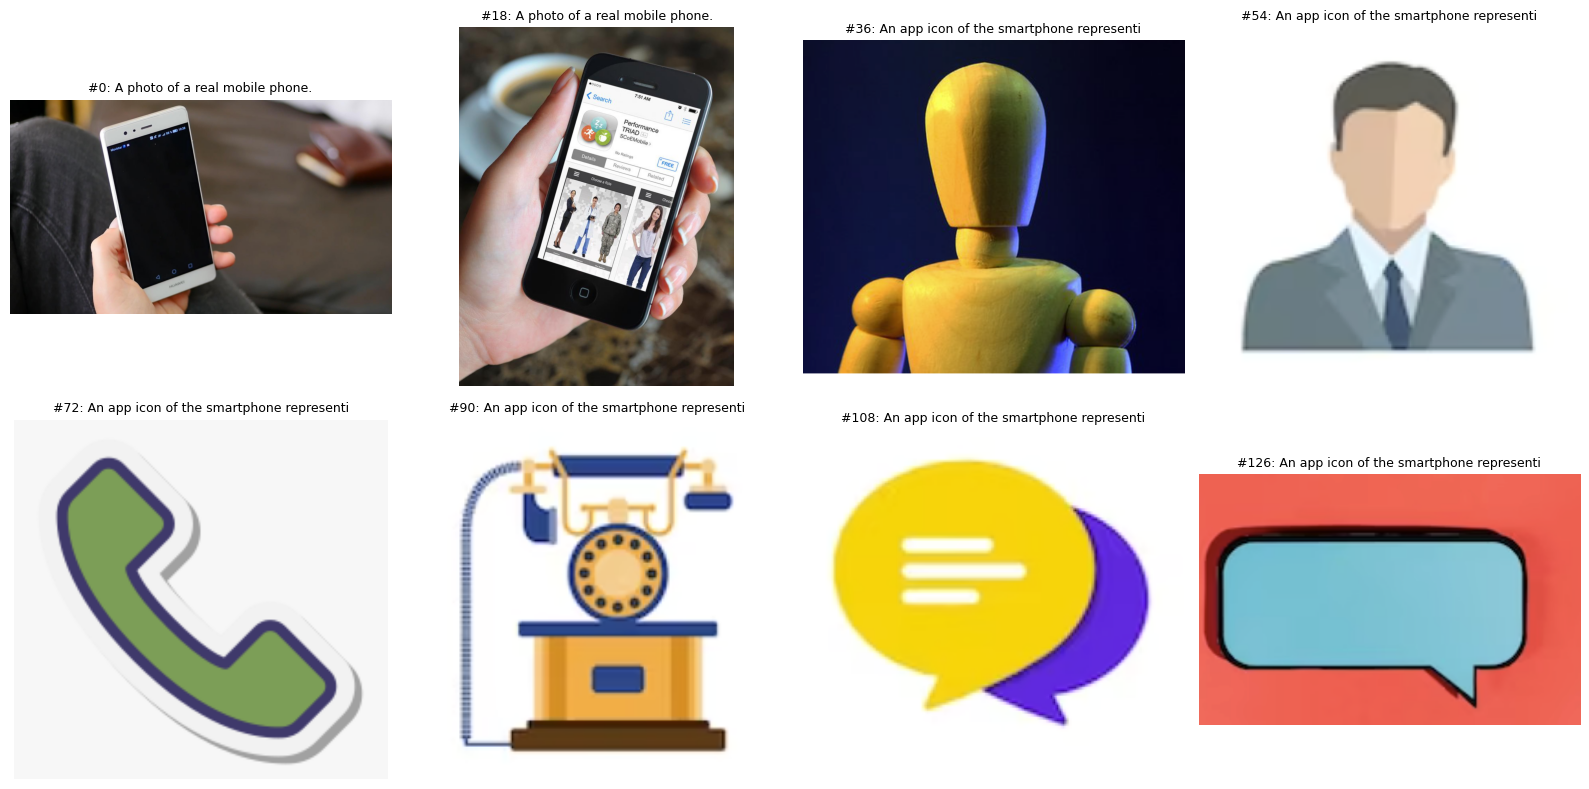

In [4]:
# View sample images with captions
import matplotlib.pyplot as plt

images = image_dataset["train"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, idx in zip(axes.ravel(), range(0, 140, 18)):   # 8 images spread across the dataset
    ax.imshow(images[idx]["image"])
    ax.set_title(f"#{idx}: {images[idx]['text'][:40]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Caption summary**

In [5]:
# Caption types and full captions
captions = pd.Series(images["text"])

# Group by the start of the caption to see the image types
caption_type = captions.str.split().str[:4].str.join(" ")
print("Caption types:")
print(caption_type.value_counts())

print("\nSome full captions:")
for idx in [0, 18, 36, 54, 72, 90]:
    print(f"#{idx}: {captions[idx]}")

Caption types:
An app icon of    105
A photo of a       35
Name: count, dtype: int64

Some full captions:
#0: A photo of a real mobile phone.
#18: A photo of a real mobile phone.
#36: An app icon of the smartphone representing the person avatar.
#54: An app icon of the smartphone representing the person avatar.
#72: An app icon of the smartphone representing the phone.
#90: An app icon of the smartphone representing the phone.


In [6]:
# get all unique captions and their counts
print("Unique captions:", captions.nunique())
print(captions.value_counts())

Unique captions: 4
A photo of a real mobile phone.                                  35
An app icon of the smartphone representing the person avatar.    35
An app icon of the smartphone representing the phone.            35
An app icon of the smartphone representing the speech bubble.    35
Name: count, dtype: int64


**Loading the Amazon reviews dataset**

In [7]:
# Load the Amazon cell phones reviews from Kaggle dataset
import kagglehub
from pathlib import Path

try:
    data_path = Path(kagglehub.dataset_download("grikomsn/amazon-cell-phones-reviews"))
    print("Downloaded to:", data_path)
except Exception as error:
    print("Download failed:", error)
    data_path = Path("/content")   # fallback: files uploaded manually

# Show the CSV files found
for file in data_path.rglob("*.csv"):
    print(file.name)

Using Colab cache for faster access to the 'amazon-cell-phones-reviews' dataset.
Downloaded to: /kaggle/input/amazon-cell-phones-reviews
20191226-items.csv
20191226-reviews.csv


In [8]:
# Read the CSV files
items = pd.read_csv(data_path / "20191226-items.csv")
reviews = pd.read_csv(data_path / "20191226-reviews.csv")

print("Items:", items.shape)
print("Reviews:", reviews.shape)

display(items.head(3))
display(reviews.head(3))

Items: (720, 10)
Reviews: (67986, 8)


,asin,brand,title,url,image,rating,reviewUrl,totalReviews,price,originalPrice
0,B0000SX2UC,NaN,Dual-Band / Tri-Mode Sprint PCS Phone w/ Voice...,https://www.amazon.com/Dual-Band-Tri-Mode-Acti...,https://m.media-amazon.com/images/I/2143EBQ210...,3.0,https://www.amazon.com/product-reviews/B0000SX2UC,14,0.00,0.0
1,B0009N5L7K,Motorola,Motorola I265 phone,https://www.amazon.com/Motorola-i265-I265-phon...,https://m.media-amazon.com/images/I/419WBAVDAR...,3.0,https://www.amazon.com/product-reviews/B0009N5L7K,7,49.95,0.0
2,B000SKTZ0S,Motorola,MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE C...,https://www.amazon.com/MOTOROLA-C168i-CINGULAR...,https://m.media-amazon.com/images/I/71b+q3ydkI...,2.7,https://www.amazon.com/product-reviews/B000SKTZ0S,22,99.99,0.0


,asin,name,rating,date,verified,title,body,helpfulVotes
0,B0000SX2UC,Janet,3,"October 11, 2005",False,"Def not best, but not worst",I had the Samsung A600 for awhile which is abs...,1.0
1,B0000SX2UC,Luke Wyatt,1,"January 7, 2004",False,Text Messaging Doesn't Work,Due to a software issue between Nokia and Spri...,17.0
2,B0000SX2UC,Brooke,5,"December 30, 2003",False,Love This Phone,"This is a great, reliable phone. I also purcha...",5.0


Inspecting the Kaggle data

In [9]:
# Check missing values
print("Missing values in items:")
print(items.isna().sum())

print("\nMissing values in reviews:")
print(reviews.isna().sum())

Missing values in items:
asin             0
brand            4
title            0
url              0
image            0
rating           0
reviewUrl        0
totalReviews     0
price            0
originalPrice    0
dtype: int64

Missing values in reviews:
asin                0
name                3
rating              0
date                0
verified            0
title              29
body               26
helpfulVotes    40771
dtype: int64


In [10]:
# Counting how many different brands there are.
print("Number of brands:", items["brand"].nunique())
# How many phones each brand has
print(items["brand"].value_counts())

Number of brands: 10
brand
Samsung     346
Motorola    105
Apple        63
Xiaomi       46
Nokia        44
Google       38
HUAWEI       32
Sony         27
OnePlus      10
ASUS          5
Name: count, dtype: int64


rating
1    12743
2     3915
3     4752
4     8824
5    37752
Name: count, dtype: int64


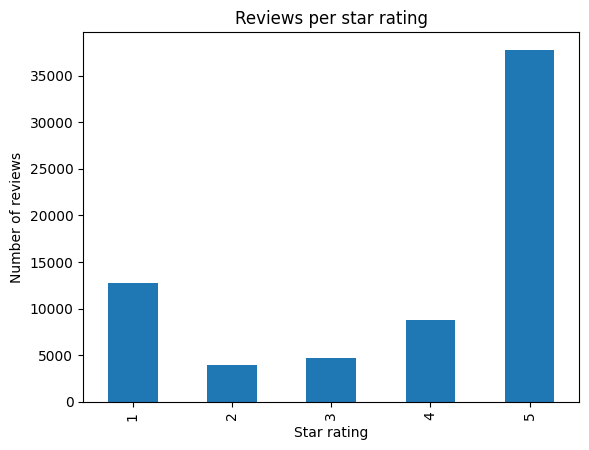

In [11]:
# Reviewing star-rating distribution
rating_counts = reviews["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", title="Reviews per star rating")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.show()

In [12]:
# Review length in words
review_words = reviews["body"].fillna("").str.split().str.len()

print(review_words.describe())
print("Empty reviews:", (review_words == 0).sum())

count    67986.000000
mean        55.291795
std        119.500034
min          0.000000
25%          8.000000
50%         23.000000
75%         56.000000
max       5345.000000
Name: body, dtype: float64
Empty reviews: 26


In [13]:
# Checking reviews link to products by asin(product id)
is_linked = reviews["asin"].isin(items["asin"])

print("Reviews linked to a product:", is_linked.sum(), "of", len(reviews))
print("Products that have reviews:", reviews["asin"].nunique(), "of", len(items))

Reviews linked to a product: 67986 of 67986
Products that have reviews: 720 of 720


**Reviews dataset findings summary:**
- 720 phones from 10 brands (Samsung has 346). Only 4 missing brands.
- Total 67,986 reviews. All link to a product by `asin`. 26 empty reviews will be removed.
- Ratings are unbalanced: approx 68% positive (4–5 stars), approx 25% negative (1–2), approx 7% neutral (3).
- Most reviews are short (median 23 words). We will truncate the long reviews.

# Task 1 - Advertisement Generation

**1(1) Candidate image selection**

Loading the vision-language model (VLM)

In [14]:
#Load the VLM and its processor
from transformers import AutoProcessor, AutoModelForMultimodalLM

VLM_MODEL_ID = "Qwen/Qwen3.5-2B"
MODEL_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

processor = AutoProcessor.from_pretrained(
    VLM_MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=448 * 448,
)
vlm_model = AutoModelForMultimodalLM.from_pretrained(
    VLM_MODEL_ID,
    dtype=MODEL_DTYPE,
    device_map=DEVICE,
)
vlm_model.eval()
print("VLM loaded:", VLM_MODEL_ID)

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 4.55GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

VLM loaded: Qwen/Qwen3.5-2B


Generating caption for images

In [15]:
# Caption function
CAPTION_PROMPT = (
    "Describe this image in one or two sentences for an online phone shop. "
    "Mention the main object, its colours, and any visible details."
)

def generate_caption_from_image(image, text_prompt=None, max_new_tokens=90):
    """Caption or answer a question about one PIL image."""
    image = image.convert("RGB")
    question = (text_prompt or CAPTION_PROMPT).strip()

    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": question},
        ]}
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = inputs.to(vlm_model.device, dtype=MODEL_DTYPE)

    input_length = inputs["input_ids"].shape[-1]
    with torch.inference_mode():
        output_ids = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)

    new_tokens = output_ids[0][input_length:]
    return processor.decode(new_tokens, skip_special_tokens=True).strip()


# Testing on the first image
print("Original caption:", images[0]["text"])
print("VLM caption:", generate_caption_from_image(images[0]["image"]))

Original caption: A photo of a real mobile phone.


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[t

VLM caption: A sleek white Huawei smartphone is held in a hand, displaying a black screen with visible status icons and navigation buttons — ideal for showcasing its design and build quality. The phone’s clean lines and minimalist aesthetic make it perfect for online listings, especially if you’re highlighting its modern appeal or compatibility with Android devices.


**Factual caption prompt**

The first Prompt added marketing language, so now we ask only for visible facts. It is tested on one image from each group.

#0 | A photo of a real mobile phone.
   VLM (2.5s): A white smartphone with a black screen is held in a person's hand, showing the time 12:25 and a few status icons, with a brown leather-bound book resting on a dark surface in the background.



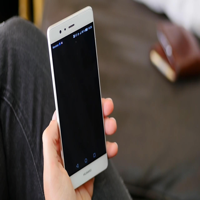

#35 | An app icon of the smartphone representing the person avatar.
   VLM (2.1s): A wooden mannequin with a smooth, rounded head and articulated joints stands against a deep blue background, illuminated by soft lighting that highlights its pale yellow hue and subtle grain texture.



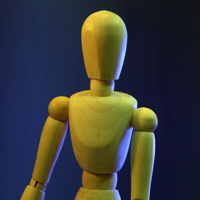

#70 | An app icon of the smartphone representing the phone.
   VLM (1.6s): A purple and blue outlined telephone handset icon is centered within a rounded square frame, featuring a gradient from purple to blue along its edges.



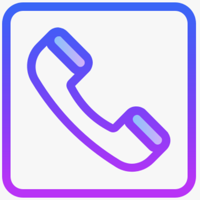

#105 | An app icon of the smartphone representing the speech bubble.
   VLM (1.5s): A yellow 3D speech bubble with a pointed tail is centered on a solid blue background.



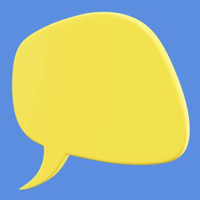

In [16]:
# Factual prompt, tested on one image per group
CAPTION_PROMPT = (
    "Describe only what is visible in this image in one sentence. "
    "Mention the main object, its colours, and any visible details. "
    "Do not add opinions or marketing language."
)

import time

for idx in [0, 35, 70, 105]:      # first image of each group
    start = time.time()
    caption = generate_caption_from_image(images[idx]["image"])
    seconds = time.time() - start # checking the elpsed time for generating the caption
    print(f"#{idx} | {images[idx]['text']}")
    print(f"   VLM ({seconds:.1f}s): {caption}\n")
    image = images[idx]["image"]
    display(image.resize((200, 200)))

**Generate Caption for all images and saving to csv for future reuse in case of gpu disconnect**

Combines the original caption (category) with the VLM caption (details)

In [17]:
# Caption all the 140 images and save
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
CAPTIONS_FILE = OUTPUT_DIR / "image_captions.csv"

if CAPTIONS_FILE.exists():
    captions_df = pd.read_csv(CAPTIONS_FILE)
    print("Loaded saved captions:", len(captions_df))
else:
    rows = []
    for idx in range(len(images)):
        vlm_caption = generate_caption_from_image(images[idx]["image"])
        rows.append({
            "index": idx,
            "original_caption": images[idx]["text"],
            "vlm_caption": vlm_caption,
        })
        if (idx + 1) % 20 == 0:
            print(f"Captioned {idx + 1} / {len(images)}")

    captions_df = pd.DataFrame(rows)
    captions_df["full_caption"] = captions_df["original_caption"] + " " + captions_df["vlm_caption"]
    captions_df.to_csv(CAPTIONS_FILE, index=False)
    print("Saved to", CAPTIONS_FILE)

display(captions_df.head())

Loaded saved captions: 140


,index,original_caption,vlm_caption,full_caption,group,clean_label
0,0,A photo of a real mobile phone.,A white smartphone with a black screen is held...,Photo of a real mobile phone. A white smartpho...,0,Photo of a real mobile phone.
1,1,A photo of a real mobile phone.,A black smartphone lies on a light gray surfac...,Photo of a real mobile phone. A black smartpho...,0,Photo of a real mobile phone.
2,2,A photo of a real mobile phone.,A hand holds a black smartphone displaying the...,Photo of a real mobile phone. A hand holds a b...,0,Photo of a real mobile phone.
3,3,A photo of a real mobile phone.,A pink smartphone with a visible keyboard inte...,Photo of a real mobile phone. A pink smartphon...,0,Photo of a real mobile phone.
4,4,A photo of a real mobile phone.,A hand holds a black smartphone displaying a W...,Photo of a real mobile phone. A hand holds a b...,0,Photo of a real mobile phone.


**Candidate Image Selection**

In [18]:
# Embed every caption with 'all-MiniLM-L6-v2'
from sentence_transformers import SentenceTransformer

print("Unique VLM captions:", captions_df["vlm_caption"].nunique(), "of", len(captions_df))

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

caption_embeddings = embedding_model.encode(
    captions_df["full_caption"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
)

print("Embedding matrix shape:", caption_embeddings.shape)

Unique VLM captions: 140 of 140


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Embedding matrix shape: (140, 384)


**Define the image search by keywords and testing**

It searches the embedded captions and finds similarity

,index,original_caption,vlm_caption,score
0,0,A photo of a real mobile phone.,A white smartphone with a black screen is held...,0.706766
4,4,A photo of a real mobile phone.,A hand holds a black smartphone displaying a W...,0.690498
28,28,A photo of a real mobile phone.,"A hand holds a bright green Nokia smartphone, ...",0.667247
9,9,A photo of a real mobile phone.,A person holds a white smartphone with a black...,0.665256
5,5,A photo of a real mobile phone.,"A black Nokia N90 smartphone is held in hands,...",0.652174
18,18,A photo of a real mobile phone.,A hand holds a black smartphone displaying the...,0.638462
15,15,A photo of a real mobile phone.,A hand holds a black smartphone displaying a c...,0.631569
102,102,An app icon of the smartphone representing the...,A vintage rotary telephone with a cream-colore...,0.604483


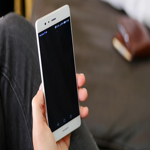

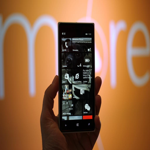

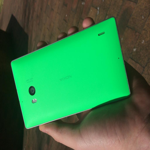

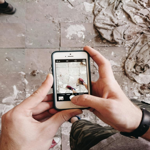

In [19]:
# Searching images by keywords
def search_images(query):
    """Score every image against the query and sort by similarity."""
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]

    similarities = caption_embeddings @ query_embedding

    results = captions_df[["index", "original_caption", "vlm_caption"]].copy()
    results["score"] = similarities
    return results.sort_values("score", ascending=False)


# Test one query
query = "a black phone held in a hand"
results = search_images(query)
display(results.head(8))

for idx in results["index"].head(4):
    display(images[int(idx)]["image"].resize((150, 150)))

**Choose a threshold**

The 4 image groups (35 in each) act as ground truth. We test simple category queries at different thresholds and measure precision and recall.

In [20]:
# Evaluate thresholds with the 4 groups (35 images in each group)
captions_df["group"] = captions_df["index"] // 35   # 0 = phone photo, 1 = avatar, 2 = phone icon, 3 = speech bubble

test_queries = {
    # similar words to the original captions
    "a real mobile phone": 0,
    "a person avatar icon": 1,
    "a phone call icon": 2,
    "a speech bubble icon": 3,
    # paraphrased words, same meaning
    "someone holding a smartphone": 0,
    "a user profile picture": 1,
    "calling or dialing symbol": 2,
    "chat or messaging symbol": 3,
}

rows = []
for threshold in [0.3, 0.4, 0.5, 0.6]:
    for query, true_group in test_queries.items():
        results = search_images(query)
        matched = results[results["score"] >= threshold]
        correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

        precision = correct / len(matched) if len(matched) > 0 else 0
        recall = correct / 35
        rows.append({"threshold": threshold, "query": query, "matched": len(matched),
                     "precision": round(precision, 2), "recall": round(recall, 2)})

threshold_table = pd.DataFrame(rows)
display(threshold_table.groupby("threshold")[["precision", "recall"]].mean().round(2))

,precision,recall
threshold,,
0.3,0.42,1.00
0.4,0.70,1.00
0.5,0.90,0.98
0.6,1.00,0.79


**Per-query results at threshold 0.45**

Threshold 0.45 balances high recall (find all matching images) with reasonable precision, based on the results above.

In [21]:
# Per-query results at threshold 0.45
MATCH_THRESHOLD = 0.45

rows = []
for query, true_group in test_queries.items():
    results = search_images(query)
    matched = results[results["score"] >= MATCH_THRESHOLD]
    correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

    precision = correct / len(matched) if len(matched) > 0 else 0
    recall = correct / 35
    rows.append({"query": query, "matched": len(matched),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

display(pd.DataFrame(rows))

,query,matched,precision,recall
0,a real mobile phone,62,0.56,1.0
1,a person avatar icon,35,1.00,1.0
2,a phone call icon,82,0.43,1.0
3,a speech bubble icon,37,0.95,1.0
4,someone holding a smartphone,58,0.60,1.0
5,a user profile picture,35,1.00,1.0
6,calling or dialing symbol,35,1.00,1.0
7,chat or messaging symbol,38,0.92,1.0


**Clean the captions**

The template word "smartphone" appears in every caption and confuses phone-related queries. We replace each original caption with a short label plus purpose tags, then re-embed.

In [22]:
# Clean captions adding purposes, re-embed, and re-test
clean_labels = {
    "A photo of a real mobile phone.": "Photo of a real mobile phone.",
    "An app icon of the smartphone representing the person avatar.": "App icon: person avatar (user profile, account).",
    "An app icon of the smartphone representing the phone.": "App icon: phone handset (call, dialing).",
    "An app icon of the smartphone representing the speech bubble.": "App icon: speech bubble (chat, messaging).",
}

captions_df["clean_label"] = captions_df["original_caption"].map(clean_labels)
captions_df["full_caption"] = captions_df["clean_label"] + " " + captions_df["vlm_caption"]

caption_embeddings = embedding_model.encode(
    captions_df["full_caption"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
)

rows = []
for query, true_group in test_queries.items():
    results = search_images(query)
    matched = results[results["score"] >= MATCH_THRESHOLD]
    correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

    precision = correct / len(matched) if len(matched) > 0 else 0
    recall = correct / 35
    rows.append({"query": query, "matched": len(matched),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

display(pd.DataFrame(rows))

,query,matched,precision,recall
0,a real mobile phone,62,0.56,1.0
1,a person avatar icon,35,1.00,1.0
2,a phone call icon,82,0.43,1.0
3,a speech bubble icon,37,0.95,1.0
4,someone holding a smartphone,58,0.60,1.0
5,a user profile picture,35,1.00,1.0
6,calling or dialing symbol,35,1.00,1.0
7,chat or messaging symbol,38,0.92,1.0


**VQA double check**

Embedding search finds candidates; the VLM then looks at each candidate image and answers yes/no to remove wrong matches.

In [23]:
# VQA double check on candidates
def vlm_says_yes(image, query):
    """Ask the VLM whether the image matches the query. Returns True or False."""
    question = f"Does this image show {query}? Answer only yes or no."
    answer = generate_caption_from_image(image, text_prompt=question, max_new_tokens=5)
    return answer.lower().startswith("yes")


def find_matching_images(query, threshold=MATCH_THRESHOLD, use_vqa=True):
    """Step 1: embedding search. Step 2 (optional): VQA check on each candidate."""
    results = search_images(query)
    candidates = results[results["score"] >= threshold].copy()

    if use_vqa:
        candidates["vqa_yes"] = [vlm_says_yes(images[int(idx)]["image"], query)
                                 for idx in candidates["index"]]
        candidates = candidates[candidates["vqa_yes"]]
    return candidates


# Test on the weakest query
query = "a phone call icon"
matches = find_matching_images(query)
correct = (captions_df.loc[matches.index, "group"] == test_queries[query]).sum()
print("Matched:", len(matches), "| precision:", round(correct / len(matches), 2), "| recall:", round(correct / 35, 2))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Matched: 27 | precision: 0.93 | recall: 0.71


**Investigate VQA rejections **

VQA raised precision (0.43 -> 0.93) but lowered recall (1.00 -> 0.71), so we check which correct images it wrongly rejected.

Correct images rejected by VQA: 10


,index,vlm_caption,score
103,103,A purple rotary telephone with a matching hand...,0.812528
102,102,A vintage rotary telephone with a cream-colore...,0.810702
100,100,A vintage-style pink telephone with a coiled c...,0.807102
95,95,A glossy red rotary telephone with a coiled re...,0.803934
104,104,A glossy black rotary telephone with an orange...,0.798272
86,86,A light blue mobile phone with a yellow screen...,0.794475
77,77,A white smartphone icon is centered within a c...,0.794135
101,101,A glossy orange rotary telephone with a matchi...,0.792851
97,97,A light blue rotary telephone with a matching ...,0.782165
81,81,A black smartphone with a light blue screen di...,0.733388


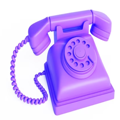

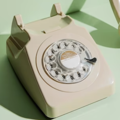

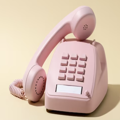

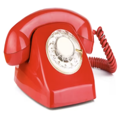

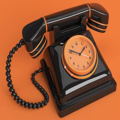

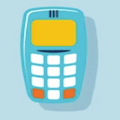

In [24]:
# Which correct images did VQA reject?
candidates = find_matching_images(query, use_vqa=False)       # before VQA
true_group = test_queries[query]

rejected = candidates[
    (captions_df.loc[candidates.index, "group"] == true_group)  # correct group
    & (~candidates["index"].isin(matches["index"]))             # but removed by VQA
]

print("Correct images rejected by VQA:", len(rejected))
display(rejected[["index", "vlm_caption", "score"]])

for idx in rejected["index"].head(6):
    display(images[int(idx)]["image"].resize((120, 120)))

**VQA only for borderline scores**

Rejected correct images had high scores (0.73–0.81), so we trust high-score matches and use VQA only for borderline ones. We test different "confident" levels on all queries.

In [25]:
# Using VQA only for borderline scores, tested on all queries
def find_matching_images(query, threshold=MATCH_THRESHOLD, confident_score=0.7):
    """Keep high scores, VQA-check borderline scores, reject low scores."""
    results = search_images(query)
    candidates = results[results["score"] >= threshold].copy()

    keep = []
    for idx, score in zip(candidates["index"], candidates["score"]):
        if score >= confident_score:
            keep.append(True)                                    # confident: keep
        else:
            keep.append(vlm_says_yes(images[int(idx)]["image"], query))  # borderline: ask VLM
    return candidates[keep]


rows = []
for confident_score in [0.65, 0.70, 0.75]:
    for query, true_group in test_queries.items():
        matches = find_matching_images(query, confident_score=confident_score)
        correct = (captions_df.loc[matches.index, "group"] == true_group).sum()

        precision = correct / len(matches) if len(matches) > 0 else 0
        recall = correct / 35
        rows.append({"confident_score": confident_score, "query": query,
                     "precision": round(precision, 2), "recall": round(recall, 2)})

vqa_table = pd.DataFrame(rows)
display(vqa_table.groupby("confident_score")[["precision", "recall"]].mean().round(2))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

,precision,recall
confident_score,,
0.65,0.98,0.86
0.70,0.98,0.82
0.75,0.98,0.82


**Checking Lower confident levels**

Lower confident levels gave better recall with the same precision, so we also test 0.55 and 0.60 and check results per query.

In [26]:
#Checking lower confident levels and show per-query results
rows = []
for confident_score in [0.55, 0.60]:
    for query, true_group in test_queries.items():
        matches = find_matching_images(query, confident_score=confident_score)
        correct = (captions_df.loc[matches.index, "group"] == true_group).sum()

        precision = correct / len(matches) if len(matches) > 0 else 0
        recall = correct / 35
        rows.append({"confident_score": confident_score, "query": query,
                     "precision": round(precision, 2), "recall": round(recall, 2)})

vqa_table_low = pd.DataFrame(rows)
display(vqa_table_low.groupby("confident_score")[["precision", "recall"]].mean().round(2))
display(vqa_table_low)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

,precision,recall
confident_score,,
0.55,0.98,0.96
0.60,0.98,0.91


,confident_score,query,precision,recall
0,0.55,a real mobile phone,0.97,1.00
1,0.55,a person avatar icon,1.00,1.00
2,0.55,a phone call icon,0.90,1.00
3,0.55,a speech bubble icon,0.95,1.00
4,0.55,someone holding a smartphone,1.00,0.71
5,0.55,a user profile picture,1.00,0.97
6,0.55,calling or dialing symbol,1.00,0.97
7,0.55,chat or messaging symbol,1.00,1.00
8,0.60,a real mobile phone,0.97,1.00
9,0.60,a person avatar icon,1.00,1.00


**Final matcher settings**

Best result: similarity threshold 0.45, VQA for scores 0.45–0.55, keep scores greater or equal 0.55. Precision 0.98, recall 0.96. Lower recall on "someone holding a smartphone" is partly due to ground truth: not every phone photo shows a hand.

In [27]:
# Save final settings and evaluation results
CONFIDENT_SCORE = 0.55

final_results = vqa_table_low[vqa_table_low["confident_score"] == CONFIDENT_SCORE]
final_results.to_csv(OUTPUT_DIR / "image_matching_results.csv", index=False)
captions_df.to_csv(CAPTIONS_FILE, index=False)   # now also includes clean_label and group

print("Final threshold:", MATCH_THRESHOLD, "| confident score:", CONFIDENT_SCORE)
print("Saved evaluation results and updated captions.")

Final threshold: 0.45 | confident score: 0.55
Saved evaluation results and updated captions.


**Extra evaluation: attribute queries**

The 4 groups only test categories. To test a wider range of requests, we hand-label the 35 phone photos (colour, held in a hand) and test new queries not used for tuning.

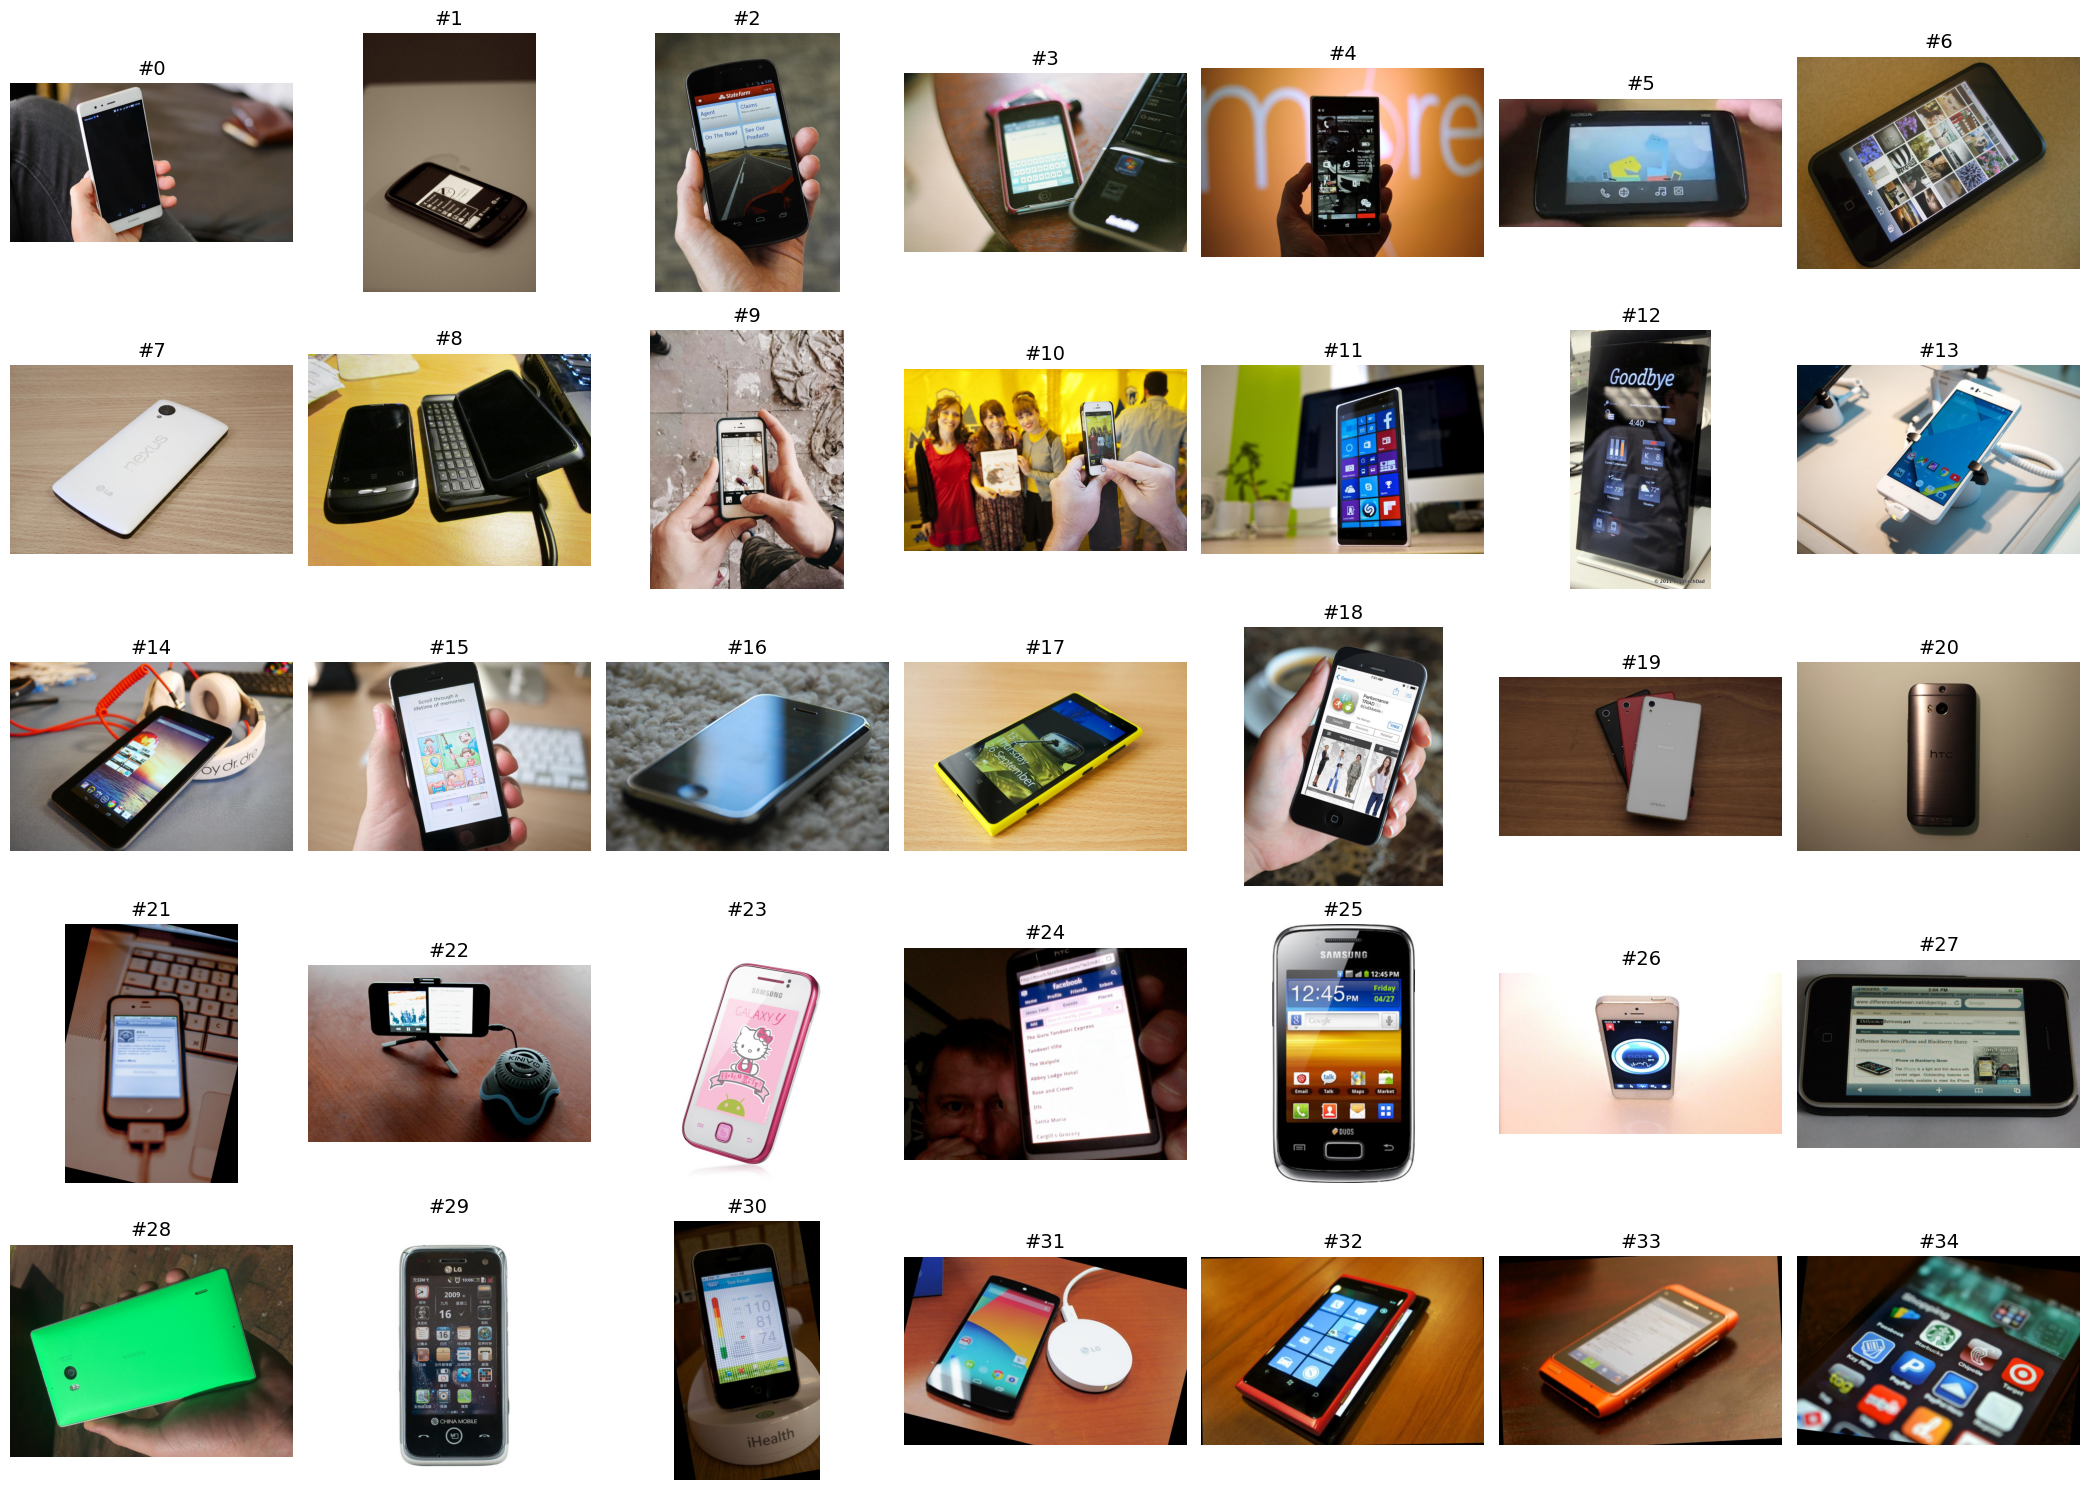

In [28]:
# Show the 35 phone photos for hand labelling
fig, axes = plt.subplots(5, 7, figsize=(21, 15))
for ax, idx in zip(axes.ravel(), range(35)):
    ax.imshow(images[idx]["image"])
    ax.set_title(f"#{idx}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [30]:
# Hand labels for the 35 phone photos
#hand label format img_index: color, held in hand (yes/no)
hand_labels_text = """
0: white, yes
1: black, no
2: black, yes
3: black, no
4: black, yes
5: black, yes
6: black, no
7: white, no
8: black, no
9: white, yes
10: white, yes
11: black, no
12: black, no
13: white, no
14: black, no
15: black, yes
16: black, no
17: yellow, no
18: black, yes
19: black/red/white, no
20: unsure, no
21: white, no
22: black, no
23: pink, no
24: unsure, yes
25: black, no
26: white, no
27: black, no
28: green, yes
29: black, no
30: black, no
31: black, no
32: red, no
33: red, no
34: black, no
"""

rows = []
for line in hand_labels_text.strip().split("\n"):
    idx, values = line.split(":")
    colour, held = values.split(",")
    rows.append({"index": int(idx), "colour": colour.strip(), "held": held.strip()})

hand_labels = pd.DataFrame(rows)
hand_labels.to_csv(OUTPUT_DIR / "phone_hand_labels.csv", index=False)

print(hand_labels["colour"].value_counts())
print(hand_labels["held"].value_counts())

colour
black              20
white               7
red                 2
unsure              2
black/red/white     1
yellow              1
pink                1
green               1
Name: count, dtype: int64
held
no     25
yes    10
Name: count, dtype: int64


**Attribute queries: group labels only vs full method**

New queries on colour and hand-holding, checked against our hand labels, show whether image details improve matching beyond the group labels.

In [31]:
# Attribute queries — group labels only vs full method
# Ground truth for each new query: which phone photos are correct (from hand labels)
attribute_queries = {
    "a black phone": hand_labels["colour"].str.contains("black"),
    "a white phone": hand_labels["colour"].str.contains("white"),
    "a red phone": hand_labels["colour"].str.contains("red"),
    "a phone held in a hand": hand_labels["held"] == "yes",
    "a white phone held in a hand": hand_labels["colour"].str.contains("white") & (hand_labels["held"] == "yes"),
}
unsure_colour = hand_labels.loc[hand_labels["colour"] == "unsure", "index"].tolist()

# Group-labels-only embeddings (no VLM details)
group_embeddings = embedding_model.encode(
    captions_df["clean_label"].tolist(), convert_to_numpy=True, normalize_embeddings=True)

rows = []
for query, is_correct in attribute_queries.items():
    true_indices = set(hand_labels.loc[is_correct, "index"])
    skip = set(unsure_colour) if "held" not in query or "white" in query else set()

    #  group labels only
    query_embedding = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)[0]
    group_scores = group_embeddings @ query_embedding
    group_matches = set(captions_df.loc[group_scores >= MATCH_THRESHOLD, "index"]) - skip

    # full method (clean label + VLM caption + VQA)
    full_matches = set(find_matching_images(query, confident_score=CONFIDENT_SCORE)["index"]) - skip

    for method, matched in [("group labels only", group_matches), ("full method", full_matches)]:
        correct = len(matched & true_indices)
        precision = correct / len(matched) if len(matched) > 0 else 0
        recall = correct / len(true_indices - skip)
        rows.append({"query": query, "method": method, "matched": len(matched),
                     "precision": round(precision, 2), "recall": round(recall, 2)})

attribute_results = pd.DataFrame(rows)
attribute_results.to_csv(OUTPUT_DIR / "attribute_query_results.csv", index=False)
display(attribute_results)
display(attribute_results.groupby("method")[["precision", "recall"]].mean().round(2))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

,query,method,matched,precision,recall
0,a black phone,group labels only,68,0.31,1.00
1,a black phone,full method,39,0.46,0.86
2,a white phone,group labels only,68,0.12,1.00
3,a white phone,full method,47,0.17,1.00
4,a red phone,group labels only,68,0.04,1.00
5,a red phone,full method,14,0.21,1.00
6,a phone held in a hand,group labels only,70,0.14,1.00
7,a phone held in a hand,full method,44,0.20,0.90
8,a white phone held in a hand,group labels only,68,0.04,1.00
9,a white phone held in a hand,full method,42,0.07,1.00


,precision,recall
method,,
full method,0.22,0.95
group labels only,0.13,1.00


**VQA on all candidates for attribute queries**

High-score candidates skipped VQA, so colour was never checked. We test VQA on every candidate for attribute queries.

In [32]:
# Attribute queries with VQA on every candidate
rows = []
for query, is_correct in attribute_queries.items():
    true_indices = set(hand_labels.loc[is_correct, "index"])
    skip = set(unsure_colour) if "held" not in query or "white" in query else set()

    # confident_score above 1 means every candidate is checked by VQA
    matches = set(find_matching_images(query, confident_score=1.01)["index"]) - skip

    correct = len(matches & true_indices)
    precision = correct / len(matches) if len(matches) > 0 else 0
    recall = correct / len(true_indices - skip)
    rows.append({"query": query, "matched": len(matches),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

attribute_vqa_all = pd.DataFrame(rows)
display(attribute_vqa_all)
print(attribute_vqa_all[["precision", "recall"]].mean().round(2))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

,query,matched,precision,recall
0,a black phone,21,0.71,0.71
1,a white phone,20,0.40,1.00
2,a red phone,11,0.27,1.00
3,a phone held in a hand,9,1.00,0.90
4,a white phone held in a hand,3,1.00,1.00


precision    0.68
recall       0.92
dtype: float64


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Wrong picks: 8


,index,original_caption,vlm_caption,score
87,87,An app icon of the smartphone representing the...,A red rotary telephone with a white dial and e...,0.608284
95,95,An app icon of the smartphone representing the...,A glossy red rotary telephone with a coiled re...,0.595662
89,89,An app icon of the smartphone representing the...,A brown rotary telephone with a white base and...,0.570759
23,23,A photo of a real mobile phone.,A pink Samsung Galaxy Y smartphone with a Hell...,0.558685
85,85,An app icon of the smartphone representing the...,A retro-style orange rotary telephone with a y...,0.552280
3,3,A photo of a real mobile phone.,A pink smartphone with a visible keyboard inte...,0.540481
101,101,An app icon of the smartphone representing the...,A glossy orange rotary telephone with a matchi...,0.537288
94,94,An app icon of the smartphone representing the...,A vintage-style rotary telephone with a pinkis...,0.506066


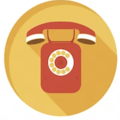

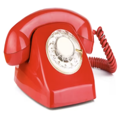

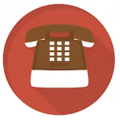

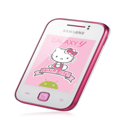

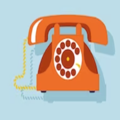

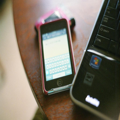

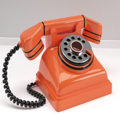

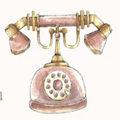

In [34]:
#Show the wrong picks for "a red phone"
query = "a red phone"
true_indices = set(hand_labels.loc[attribute_queries[query], "index"])
matches = find_matching_images(query, confident_score=1.01)

wrong = matches[~matches["index"].isin(true_indices)]
print("Wrong picks:", len(wrong))
display(wrong[["index", "original_caption", "vlm_caption", "score"]])

for idx in wrong["index"]:
    display(images[int(idx)]["image"].resize((120, 120)))

**Final matcher: route by query type**

Attribute queries (colour or hand) use VQA on every candidate; category queries use VQA only for borderline scores.

In [35]:
#Final matcher that chooses the VQA rule by query type
ATTRIBUTE_WORDS = ["black", "white", "red", "pink", "blue", "green", "yellow", "gold",
                   "silver", "grey", "gray", "orange", "purple", "brown",
                   "hand", "held", "holding"]

def match_images(query):
    """Final image matcher used by the app."""
    is_attribute_query = any(word in query.lower() for word in ATTRIBUTE_WORDS)
    if is_attribute_query:
        return find_matching_images(query, confident_score=1.01)          # VQA on all candidates
    return find_matching_images(query, confident_score=CONFIDENT_SCORE)   # VQA on borderline only


# Quick check of the routing
for query in ["a phone call icon", "a red smartphone", "someone holding a smartphone"]:
    rule = "VQA on all" if any(w in query.lower() for w in ATTRIBUTE_WORDS) else "borderline VQA"
    print(f"{query!r} -> {rule}")

'a phone call icon' -> borderline VQA
'a red smartphone' -> VQA on all
'someone holding a smartphone' -> VQA on all


**1(2) Slogan Generation**

The Qwen3.5 VLM reads the selected image directly and writes a short slogan for the named audience. Facts must come only from what is visible in the image.

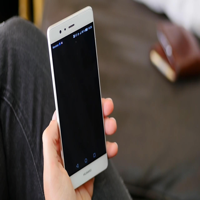

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


young tech-savvy users: Meet the Huawei Mate 9 — sleek, smart, and ready for your next big move.
busy professionals: Stay connected, work smarter—your Huawei phone, ready for the hustle.
senior citizens: Easy to use, big screen, long battery life.


In [36]:
# Generate a slogan from the image
def generate_slogan(image, audience):
    """Ask the VLM for a short slogan for this product and audience."""
    prompt = (
        f"You are an advertising copywriter for a phone shop. "
        f"Write one catchy sales slogan for the product in this image, aimed at {audience}. "
        f"Only mention features you can see in the image. Do not invent specifications. "
        f"Maximum 10 words. Output only the slogan."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


# Test: one image, three audiences
idx = 0
display(images[idx]["image"].resize((200, 200)))
for audience in ["young tech-savvy users", "busy professionals", "senior citizens"]:
    print(f"{audience}: {generate_slogan(images[idx]['image'], audience)}")

**Updating the Slogan generation prompt**

Previous prompt invented facts (model name, battery life) and exceeded 10 words. new one forbids unseen claims, asks for one visible detail, adds examples, and we check word count and risky claim words

In [38]:
#Slogan prompt update with rule checks
RISKY_WORDS = ["battery", "camera", "mp", "gb", "storage", "fast", "speed",
               "processor", "mate", "galaxy", "iphone", "pixel", "5g"]

def generate_slogan(image, audience):
    """Slogan using only visible features, aimed at the audience."""
    prompt = (
        f"You are an advertising copywriter for a phone shop.\n"
        f"Write one sales slogan for the product in this image, aimed at {audience}.\n"
        f"Rules:\n"
        f"- Use only what you can see: colour, design, shape, how it is used.\n"
        f"- Mention at least one visible detail, such as the colour.\n"
        f"- Do not mention brand or model names, battery, camera, storage, or speed.\n"
        f"- Focus on a feeling or benefit that matters to {audience}.\n"
        f"- Maximum 10 words. Output only the slogan.\n"
        f"Examples:\n"
        f"- Sleek white style that fits right in your hand.\n"
        f"- Bold colour, clear screen, made for everyday moments."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


def check_slogan(slogan):
    """Return word count and any risky claim words found."""
    words = slogan.lower().replace(",", " ").replace(".", " ").split()
    risky = [w for w in RISKY_WORDS if w in words]
    return len(words), risky


idx = 0
for audience in ["young tech-savvy users", "busy professionals", "senior citizens"]:
    slogan = generate_slogan(images[idx]["image"], audience)
    n_words, risky = check_slogan(slogan)
    print(f"{audience}: {slogan}")
    print(f"   words: {n_words} | risky words: {risky}\n")

young tech-savvy users: Bold white design, sleek touch, ready for your next big idea.
   words: 11 | risky words: []

busy professionals: Clean white design, perfect for your busy day.
   words: 8 | risky words: []

senior citizens: Soft touch, clear screen, easy to hold and use.
   words: 9 | risky words: []



**Overlay the slogan on the image**

Tests overlaying working on an image

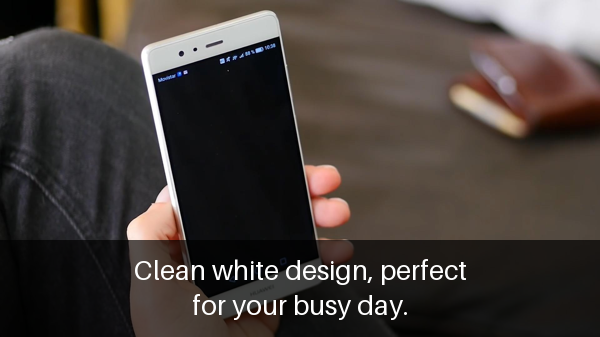

In [47]:
#Overlaying the slogan on the image
import textwrap
from PIL import Image, ImageDraw, ImageFont

FONT_PATH = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"   # font included in Colab

def add_slogan_to_image(image, slogan, width=600):
    """Return a new image with the slogan on a dark band at the bottom."""
    # Resize to a fixed width so every ad looks consistent
    slogan = slogan.replace("—", " - ").replace("–", " - ")   # characters the font may not draw
    image = image.convert("RGB")
    height = int(image.height * width / image.width)
    ad = image.resize((width, height)).convert("RGBA")

    # Font size based on image width
    font_size = max(width, height) // 22   # bigger text for tall images too
    try:
        font = ImageFont.truetype(FONT_PATH, font_size)
    except OSError:
        font = ImageFont.load_default(size=font_size)

    # Wrap the slogan into lines that fit the width
    lines = textwrap.wrap(slogan, width=28)
    line_height = int(font_size * 1.3)
    band_height = line_height * len(lines) + font_size

    # Semi-transparent dark band at the bottom
    band = Image.new("RGBA", ad.size, (0, 0, 0, 0))
    draw_band = ImageDraw.Draw(band)
    draw_band.rectangle([(0, height - band_height), (width, height)], fill=(0, 0, 0, 170))
    ad = Image.alpha_composite(ad, band)

    # White text, centred on each line
    draw = ImageDraw.Draw(ad)
    y = height - band_height + font_size // 2
    for line in lines:
        text_width = draw.textlength(line, font=font)
        draw.text(((width - text_width) / 2, y), line, font=font, fill="white")
        y += line_height

    return ad.convert("RGB")


slogan = "Clean white design, perfect for your busy day."
display(add_slogan_to_image(images[0]["image"], slogan))

**Full advertisement test: slogan + overlay**

Each audience gets a short description of its interests so slogans differ more. If a slogan contains a risky claim word, we retry once with a stricter instruction. Tested on 3 images on 3 audiences.

`generate_slogan` function is rewritten to add audience interests (with a fallback for any new audience) so slogans differ more between audiences. Earlier versions are kept above as a record of the prompt changes.

Few-shot examples were removed because the model copied them (e.g. "fits right in your hand" for a speech bubble).

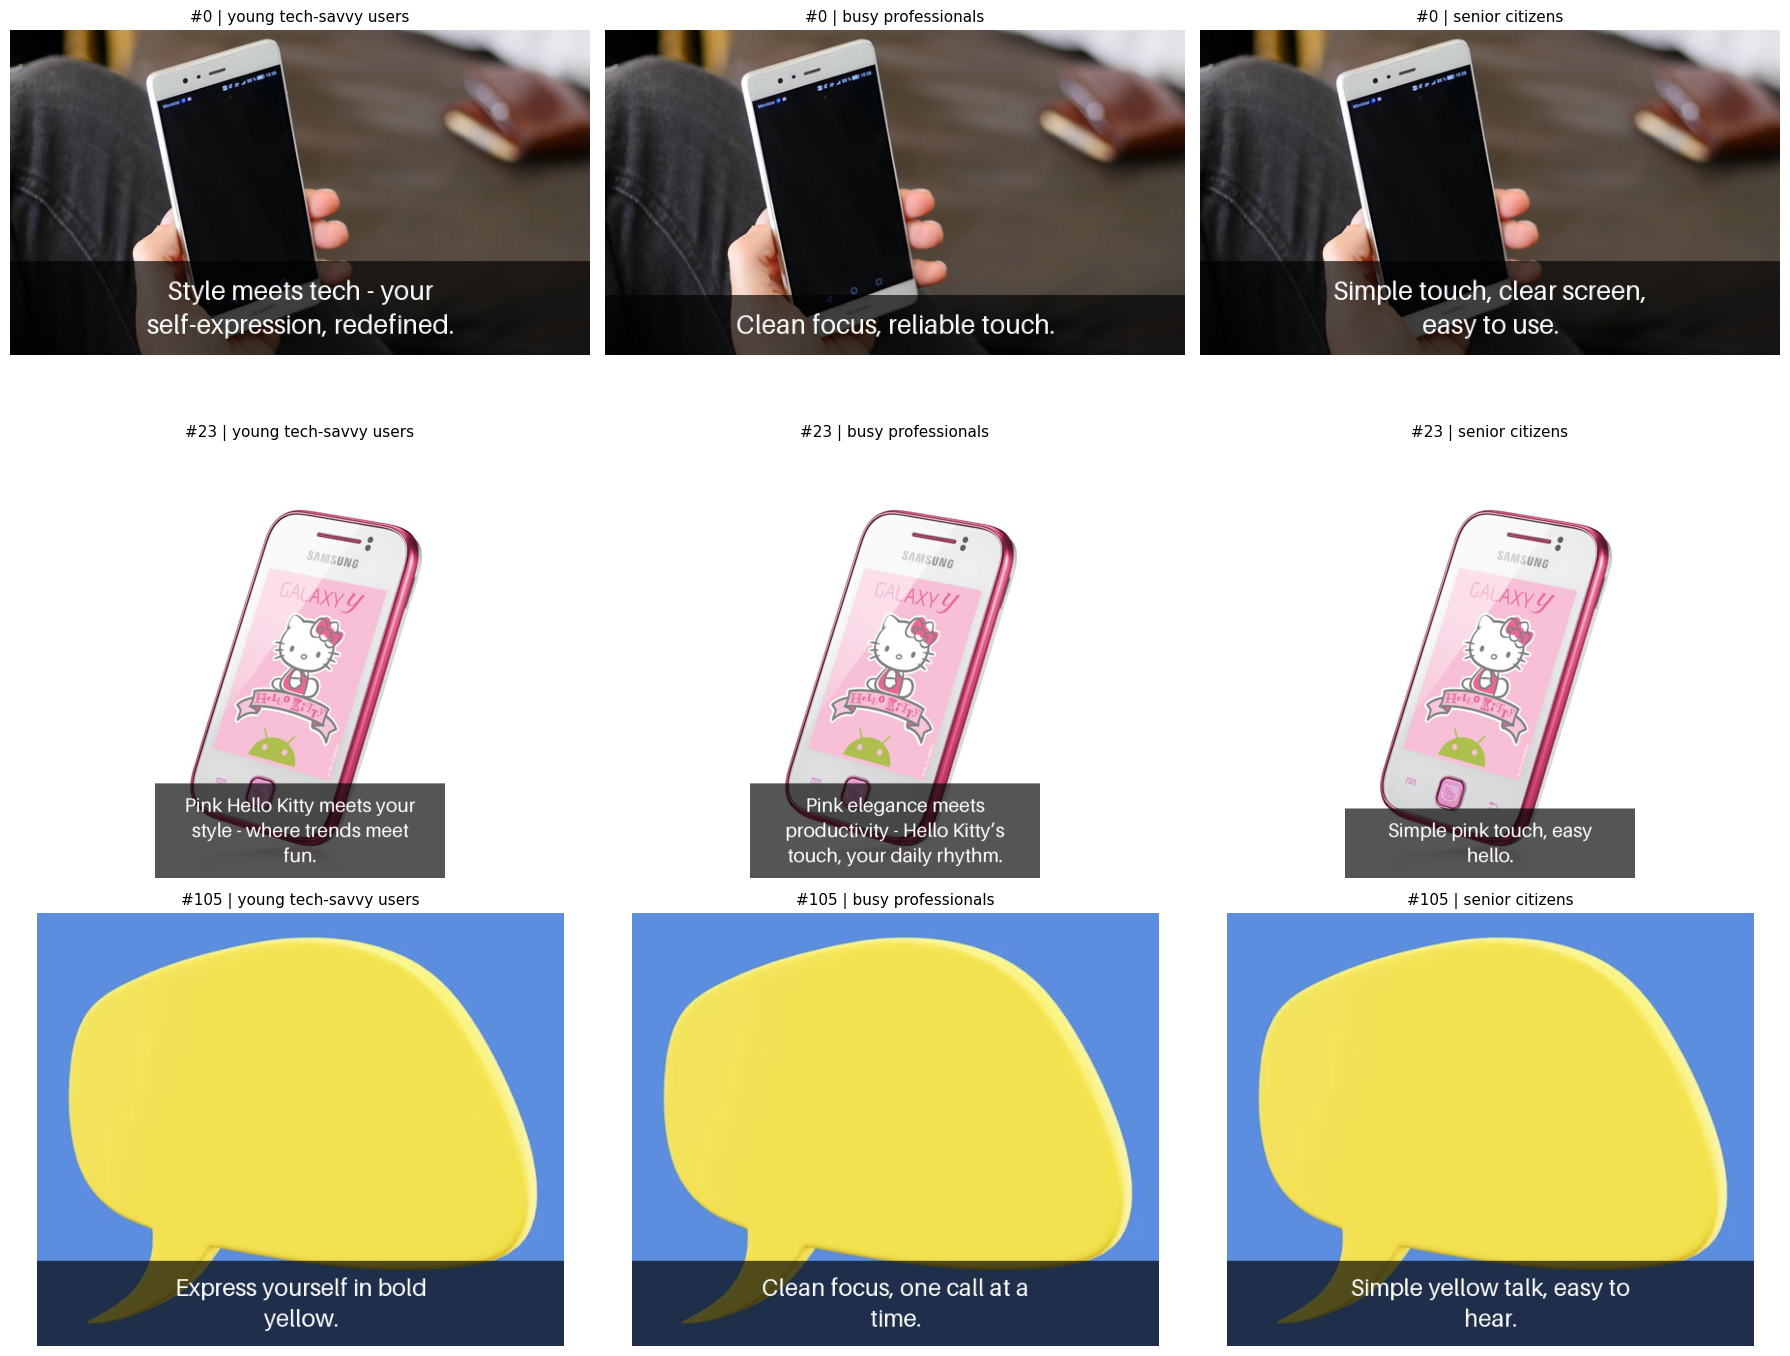

,index,audience,slogan,words,risky_words
0,0,young tech-savvy users,"Style meets tech—your self-expression, redefined.",5,[]
1,0,busy professionals,"Clean focus, reliable touch.",4,[]
2,0,senior citizens,"Simple touch, clear screen, easy to use.",7,[]
3,23,young tech-savvy users,Pink Hello Kitty meets your style—where trends meet fun.,9,[]
4,23,busy professionals,"Pink elegance meets productivity—Hello Kitty’s touch, your daily rhythm.",9,[]
5,23,senior citizens,"Simple pink touch, easy hello.",5,[]
6,105,young tech-savvy users,Express yourself in bold yellow.,5,[]
7,105,busy professionals,"Clean focus, one call at a time.",7,[]
8,105,senior citizens,"Simple yellow talk, easy to hear.",6,[]


In [48]:
# Full advertisement with audience descriptions, tested on 3 images and audiences
AUDIENCE_INTERESTS = {
    "young tech-savvy users": "they care about style, trends and self-expression",
    "busy professionals": "they care about productivity, reliability and a clean look",
    "senior citizens": "they care about simplicity, comfort and ease of use",
}

RISKY_WORDS = ["battery", "camera", "mp", "gb", "storage", "fast", "speed",
               "processor", "mate", "galaxy", "iphone", "pixel", "5g", "voice", "sound"]


def generate_slogan(image, audience, extra_rule=""):
    """Slogan using only visible features, aimed at the audience and its interests."""
    interests = AUDIENCE_INTERESTS.get(audience, "think about what this audience cares about")
    prompt = (
        f"You are an advertising copywriter for a phone shop.\n"
        f"Write one sales slogan for the product in this image, aimed at {audience} ({interests}).\n"
        f"Rules:\n"
        f"- Use only what you can see: colour, design, shape, how it is used.\n"
        f"- Mention at least one visible detail, such as the colour.\n"
        f"- Do not mention brand or model names, battery, camera, storage, speed, or sound.\n"
        f"- Focus on a feeling or benefit that matters to this audience.\n"
        f"- About 10 words. Output only the slogan.\n"
        f"{extra_rule}"
        f"- Write an original slogan for this specific image."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


def make_advertisement(image, audience):
    """Generate a checked slogan and put it on the image."""
    slogan = generate_slogan(image, audience)
    n_words, risky = check_slogan(slogan)
    if risky:   # retry once with a stricter rule naming the risky words
        extra_rule = f"- Important: do not use these words: {', '.join(risky)}.\n"
        slogan = generate_slogan(image, audience, extra_rule=extra_rule)
        n_words, risky = check_slogan(slogan)
    return add_slogan_to_image(image, slogan), slogan, n_words, risky


test_images = [0, 23, 105]      # white phone in hand, pink phone, speech bubble icon
test_audiences = list(AUDIENCE_INTERESTS.keys())

ad_rows = []
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for row, idx in enumerate(test_images):
    for col, audience in enumerate(test_audiences):
        ad, slogan, n_words, risky = make_advertisement(images[idx]["image"], audience)
        axes[row, col].imshow(ad)
        axes[row, col].set_title(f"#{idx} | {audience}", fontsize=11)
        axes[row, col].axis("off")
        ad_rows.append({"index": idx, "audience": audience, "slogan": slogan,
                        "words": n_words, "risky_words": risky})
plt.tight_layout()
plt.show()

ad_results = pd.DataFrame(ad_rows)
ad_results.to_csv(OUTPUT_DIR / "slogan_results.csv", index=False)
pd.set_option("display.max_colwidth", None)   # show full slogans
display(ad_results)

**Test a new audience (fallback)**
"Gamers" is not in AUDIENCE_INTERESTS, so the model must work out what they care about by itself.

In AUDIENCE_INTERESTS? False


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


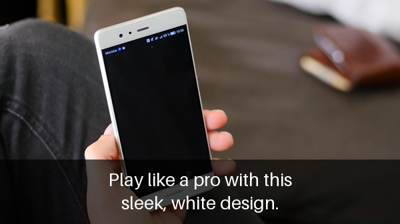

#0 | Play like a pro with this sleek, white design. | words: 9 | risky: []



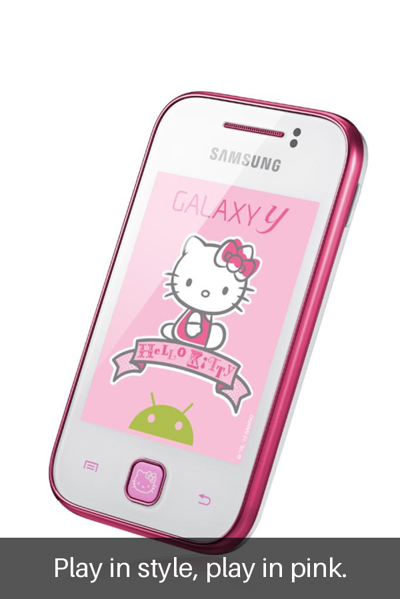

#23 | Play in style, play in pink. | words: 6 | risky: []



In [49]:
# Testing a fallback audience not in the dictionary
audience = "gamers"
print("In AUDIENCE_INTERESTS?", audience in AUDIENCE_INTERESTS)

for idx in [0, 23]:
    ad, slogan, n_words, risky = make_advertisement(images[idx]["image"], audience)
    display(ad.resize((400, int(ad.height * 400 / ad.width))))
    print(f"#{idx} | {slogan} | words: {n_words} | risky: {risky}\n")

**1(3)Advanced feature: auto-layout**

The fixed bottom band often covers the product. Auto-layout measures how "busy" (how many edges) the top, middle and bottom areas are, and places the text in the free area.

In [50]:
#Measure how busy each area of an image is
from PIL import ImageFilter

def area_busyness(image, position, band_fraction=0.25):
    """Average edge strength in the top, middle or bottom band of the image."""
    gray = image.convert("L")                         # black-and-white copy
    edges = np.array(gray.filter(ImageFilter.FIND_EDGES))
    height = edges.shape[0]
    band = int(height * band_fraction)

    if position == "top":
        area = edges[:band]
    elif position == "middle":
        area = edges[(height - band) // 2 : (height + band) // 2]
    else:  # bottom
        area = edges[height - band:]
    return area.mean()


for idx in [0, 23, 105]:
    scores = {pos: round(area_busyness(images[idx]["image"], pos), 1) for pos in ["top", "middle", "bottom"]}
    print(f"#{idx}: {scores} -> calmest: {min(scores, key=scores.get)}")

#0: {'top': np.float64(3.3), 'middle': np.float64(1.7), 'bottom': np.float64(2.1)} -> calmest: middle
#23: {'top': np.float64(6.1), 'middle': np.float64(9.3), 'bottom': np.float64(7.3)} -> calmest: top
#105: {'top': np.float64(1.6), 'middle': np.float64(0.6), 'bottom': np.float64(1.5)} -> calmest: middle


**Find a free area with the VLM**

Edge busyness alone failed: plain products (black screen, yellow bubble) looked "calm". We crop the top and bottom bands and ask the VLM whether each contains the product, using edges only as a tie-breaker.

In [51]:
# Choose the text position with the VLM
def crop_band(image, position, band_fraction=0.25):
    """Return the top or bottom band of the image."""
    band = int(image.height * band_fraction)
    if position == "top":
        return image.crop((0, 0, image.width, band))
    return image.crop((0, image.height - band, image.width, image.height))


def band_has_product(image, position):
    """Ask the VLM if this band shows part of the main object."""
    question = "Does this image show any part of a phone, a hand, or the main object? Answer only yes or no."
    answer = generate_caption_from_image(crop_band(image, position), text_prompt=question, max_new_tokens=5)
    return answer.lower().startswith("yes")


def choose_text_position(image):
    """Pick top or bottom: prefer a band without the product, then the calmer band."""
    has_product = {pos: band_has_product(image, pos) for pos in ["top", "bottom"]}
    free = [pos for pos in ["top", "bottom"] if not has_product[pos]]

    if len(free) == 1:
        return free[0], has_product
    # both free or both covered: choose the calmer band
    calmer = min(["top", "bottom"], key=lambda pos: area_busyness(image, pos))
    return calmer, has_product


for idx in [0, 23, 105]:
    position, has_product = choose_text_position(images[idx]["image"])
    print(f"#{idx}: product in band -> {has_product} | text goes: {position}")

#0: product in band -> {'top': True, 'bottom': True} | text goes: bottom
#23: product in band -> {'top': True, 'bottom': True} | text goes: top
#105: product in band -> {'top': False, 'bottom': False} | text goes: bottom


**Find the product's exact position**

Checking only "top or bottom" did not work, because the product often reaches both. So we ask the VLM to draw a box around the product. If we know where the product is, we can put the text in the empty space around it.

#0: VLM answer -> [233, 34, 537, 942]


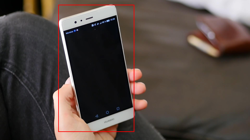

#23: VLM answer -> [122, 150, 922, 927]


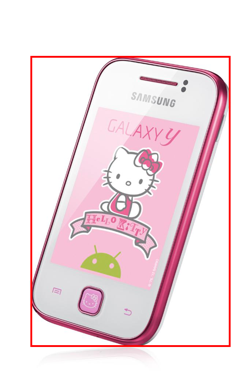

#105: VLM answer -> [68, 46, 959, 946]


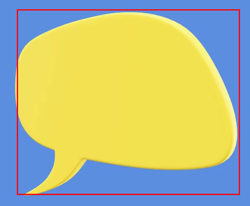

In [52]:
# Ask the VLM for the product's bounding box
import re

def find_product_box(image):
    """Ask the VLM for the main object's box. Returns (x1, y1, x2, y2) in pixels, or None."""
    question = ("Find the main object in this image. Give its bounding box as "
                "[x1, y1, x2, y2] using coordinates from 0 to 1000. Output only the four numbers.")
    answer = generate_caption_from_image(image, text_prompt=question, max_new_tokens=30)
    numbers = [int(n) for n in re.findall(r"\d+", answer)][:4]
    if len(numbers) < 4:
        return None, answer
    x1, y1, x2, y2 = numbers
    box = (x1 * image.width / 1000, y1 * image.height / 1000,
           x2 * image.width / 1000, y2 * image.height / 1000)
    return box, answer


for idx in [0, 23, 105]:
    image = images[idx]["image"].convert("RGB")
    box, answer = find_product_box(image)
    print(f"#{idx}: VLM answer -> {answer}")
    if box:
        preview = image.copy()
        ImageDraw.Draw(preview).rectangle(box, outline="red", width=5)
        display(preview.resize((250, int(250 * image.height / image.width))))